# Bayes' Theorem

Companion notebook for [Bayes' Theorem](../../notes/probability/bayes_theorem.md).

$$P(A\mid B)=\frac{P(B\mid A)P(A)}{P(B\mid A)P(A)+P(B\mid A^c)P(A^c)}.$$

We compute posteriors for screening tests, study how they depend on prevalence, update sequentially with repeated evidence, and draw a Venn-style diagram using only `matplotlib`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from itertools import product
from fractions import Fraction

rng = np.random.default_rng(42)
plt.rcParams["figure.figsize"] = (7, 3.5)
from matplotlib.patches import Circle, Rectangle

## 1. Posterior for a diagnostic test

Prevalence 2%, sensitivity 95%, false positive rate 5%. The note finds $P(D\mid+)\approx0.2794$.

In [2]:
def posterior(prior, sens, fpr):
    evidence = sens * prior + fpr * (1 - prior)
    return sens * prior / evidence, evidence

post, ev = posterior(0.02, 0.95, 0.05)
print(f"P(+) = {ev:.4f}   P(D|+) = {post:.4f}")

# BSE example: prior 2%, sensitivity 70%, false positive rate 10%
print("BSE posterior:", round(posterior(0.02, 0.70, 0.10)[0], 4))

P(+) = 0.0680   P(D|+) = 0.2794
BSE posterior: 0.125


## 2. Natural frequencies and simulation

Imagine 100,000 people. Counting the true and false positives gives the same answer as the formula.

In [3]:
n = 100_000
disease = rng.random(n) < 0.02
positive = np.where(disease, rng.random(n) < 0.95, rng.random(n) < 0.05)
print("true positives :", (disease & positive).sum())
print("false positives:", (~disease & positive).sum())
print("simulated P(D|+) =", round((disease & positive).sum() / positive.sum(), 4))

true positives : 1876
false positives: 4813
simulated P(D|+) = 0.2805


## 3. Dependence on the prior

The same test gives very different posteriors at different prevalences. For rare conditions most positives are false positives.

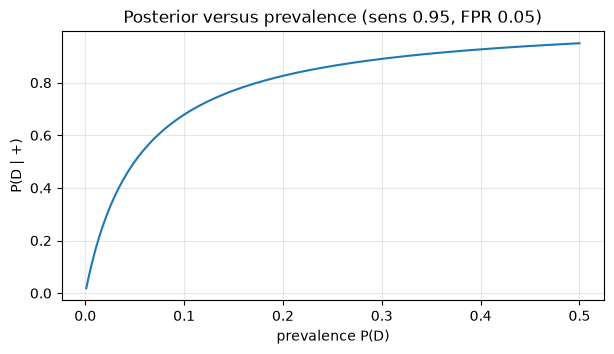

at 1%: 0.161  at 20%: 0.826


In [4]:
prev = np.linspace(0.001, 0.5, 200)
post = np.array([posterior(p, 0.95, 0.05)[0] for p in prev])
plt.plot(prev, post)
plt.xlabel("prevalence P(D)"); plt.ylabel("P(D | +)")
plt.title("Posterior versus prevalence (sens 0.95, FPR 0.05)")
plt.grid(alpha=0.3)
plt.show()
print("at 1%:", round(posterior(0.01, 0.95, 0.05)[0], 3), " at 20%:", round(posterior(0.20, 0.95, 0.05)[0], 3))

## 4. Sequential updating

If two tests are independent given the true status, the posterior after the first positive becomes the prior for the second. With prevalence 1%, sensitivity 90%, FPR 8%, one positive gives about 0.10 and two give about 0.56.

In [5]:
p = 0.01
for k in range(1, 4):
    p = posterior(p, 0.90, 0.08)[0]
    print(f"after {k} positive test(s): {p:.4f}")

# Same two-test result in one step using joint likelihoods 0.9^2 and 0.08^2
print("one-step, two tests:", round(posterior(0.01, 0.9**2, 0.08**2)[0], 4))

after 1 positive test(s): 0.1020
after 2 positive test(s): 0.5611
after 3 positive test(s): 0.9350
one-step, two tests: 0.5611


## 5. A Venn-style picture

Take $P(A)=0.3$, $P(B\mid A)=0.8$, $P(B)=0.4$. Then $P(A\cap B)=0.24$ and by Bayes $P(A\mid B)=0.8\cdot0.3/0.4=0.6$. The two circles below are drawn with fixed size; the labels carry the probabilities.

P(A and B) = 0.24  P(A|B) = 0.6


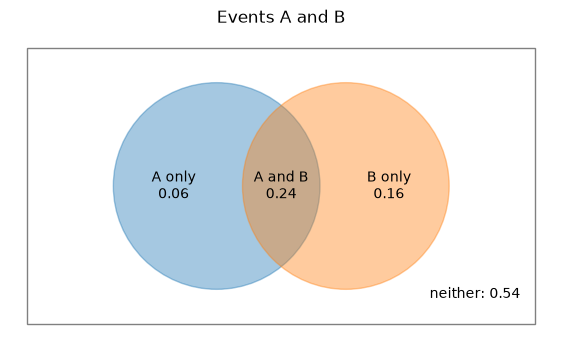

In [6]:
P_A, P_B_given_A, P_B = 0.3, 0.8, 0.4
P_AB = P_A * P_B_given_A
P_A_only, P_B_only = P_A - P_AB, P_B - P_AB
P_neither = 1 - P_A - P_B_only
print("P(A and B) =", round(P_AB, 2), " P(A|B) =", round(P_AB / P_B, 2))

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.add_patch(Rectangle((-2.2, -1.6), 5.9, 3.2, fill=False, edgecolor="gray"))
ax.add_patch(Circle((0, 0), 1.2, alpha=0.4, color="tab:blue"))
ax.add_patch(Circle((1.5, 0), 1.2, alpha=0.4, color="tab:orange"))
ax.text(-0.5, 0, f"A only\n{P_A_only:.2f}", ha="center", va="center")
ax.text(0.75, 0, f"A and B\n{P_AB:.2f}", ha="center", va="center")
ax.text(2.0, 0, f"B only\n{P_B_only:.2f}", ha="center", va="center")
ax.text(3.0, -1.3, f"neither: {P_neither:.2f}", ha="center")
ax.set_xlim(-2.4, 3.9); ax.set_ylim(-1.8, 1.8); ax.set_aspect("equal"); ax.axis("off")
ax.set_title("Events A and B")
plt.show()